In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/208.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/45.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/58.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/342.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/151.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/283.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/118.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/113.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/328.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/42.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/291.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/178.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyundai Creta/62.jpg
/kaggle/input/cars-image-dataset/Cars Dataset/test/Hyun

In [2]:
import tensorflow as tf
test_ds=tf.keras.utils.image_dataset_from_directory(
    '/kaggle/input/cars-image-dataset/Cars Dataset/test',
    image_size=(224,224),
    batch_size=32
)

2025-09-23 12:37:49.983213: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758631070.163955      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758631070.218659      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 813 files belonging to 7 classes.


I0000 00:00:1758631082.592617      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [3]:
train_ds=tf.keras.utils.image_dataset_from_directory(
    '/kaggle/input/cars-image-dataset/Cars Dataset/train',
    image_size=(224,224),
    batch_size=32
)

Found 3352 files belonging to 7 classes.


In [4]:
class_names = train_ds.class_names
print(class_names)


['Audi', 'Hyundai Creta', 'Mahindra Scorpio', 'Rolls Royce', 'Swift', 'Tata Safari', 'Toyota Innova']


In [5]:
num_classes = 7

In [6]:
from tensorflow.keras.applications.vgg16 import preprocess_input

In [7]:
train_ds=train_ds.map(lambda x,y:(preprocess_input(x),y))

In [8]:
test_ds=test_ds.map(lambda x,y:(preprocess_input(x),y))

In [9]:
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
base_model = VGG16(
    include_top=False, 
    weights="imagenet", 
    input_shape=(224, 224, 3),

)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
base_model.trainable=True
set_trainable = False

for layer in base_model.layers:
    if layer.name=='block5_conv1':
        set_trainable=True
    if set_trainable:
        layer.trainable=True
    else:
        layer.trainable=False

for layer in base_model.layers:
    print(layer.name,layer.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [11]:

model = models.Sequential([
    
    base_model,
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')  # num_classes = your dataset classes
])

In [12]:
from tensorflow.keras import optimizers

# Example: lower learning rate
  
model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',   # metric to monitor
    patience=6,           # how many epochs to wait after no improvement
    restore_best_weights=True # roll back to best weights
)

In [14]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=50,
    callbacks=[early_stopping],
        batch_size=32
)

Epoch 1/50


I0000 00:00:1758631089.018974      65 service.cc:148] XLA service 0x7d1fbc00ecd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1758631089.019743      65 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1758631089.483098      65 cuda_dnn.cc:529] Loaded cuDNN version 90300


  2/105 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.1406 - loss: 26.9493  

I0000 00:00:1758631098.550570      65 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


105/105 ━━━━━━━━━━━━━━━━━━━━ 35s 218ms/step - accuracy: 0.2318 - loss: 11.5387 - val_accuracy: 0.4465 - val_loss: 1.7743
Epoch 2/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.3917 - loss: 2.3602 - val_accuracy: 0.6310 - val_loss: 1.1039
Epoch 3/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.5691 - loss: 1.3754 - val_accuracy: 0.7208 - val_loss: 0.8475
Epoch 4/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.7015 - loss: 0.9111 - val_accuracy: 0.7749 - val_loss: 0.6795
Epoch 5/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8211 - loss: 0.5347 - val_accuracy: 0.7983 - val_loss: 0.6020
Epoch 6/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8836 - loss: 0.3475 - val_accuracy: 0.8229 - val_loss: 0.5533
Epoch 7/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - accuracy: 0.9158 - loss: 0.2592 - val_accuracy: 0.8204 - val_loss: 0.5267
Epoch 8/50
105/105 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.9451 - loss: 0.1640 - va

In [15]:
loss,acc=model.evaluate(test_ds)

26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.8916 - loss: 0.3825


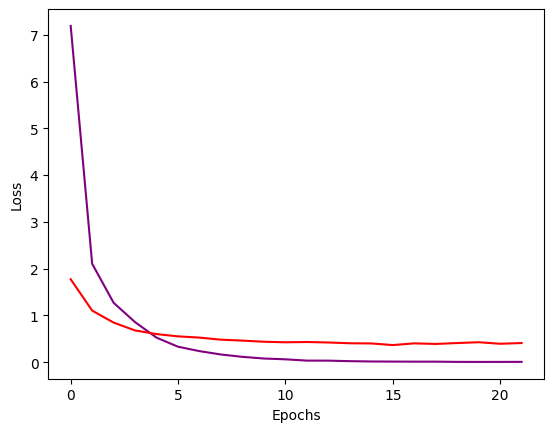

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'],label="Training Loss",color="purple")
plt.plot(history.history['val_loss'],label="Val Loss",color="red")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()